# Medical appointment data: exploratory data analysis\n\nThis EDA uses the original CSV. It documents quality, distributions, missingness, appointment outcomes, and calendar trends.\n

In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
Path('artifacts').mkdir(exist_ok=True)
df = pd.read_csv(Path('Medical_appointment_data.csv'))
df['specialty'] = df['specialty'].fillna('General')
df['disability'] = df['disability'].fillna('No')
df.drop(columns=['under_12_years_old'], inplace=True)
df.drop(columns=['over_60_years_old'], inplace=True)
df.drop(columns=['SMS_received'], inplace=True)
df.drop(columns=['patient_needs_companion'], inplace=True)
df.drop(columns=['Scholarship'], inplace=True)
print(df.shape)
display(df.head())



(109593, 21)


,specialty,appointment_time,gender,no_show,disability,place,appointment_shift,age,average_temp_day,average_rain_day,...,max_rain_day,rainy_day_before,storm_day_before,rain_intensity,heat_intensity,appointment_date_continuous,Hipertension,Diabetes,Alcoholism,Handcap
0,psychotherapy,17,F,yes,intellectual,Lake Marvinville,afternoon,9.0,23.18,0.00,...,0.0,1,1,no_rain,warm,01-01-2020,0,0,0,0
1,General,7,M,no,intellectual,ITAPEMA,morning,11.0,14.31,0.02,...,0.6,1,1,no_rain,cold,01-01-2020,0,0,0,0
2,speech therapy,16,M,no,intellectual,ITAJAÍ,afternoon,8.0,21.61,0.01,...,0.2,1,1,no_rain,warm,01-01-2020,0,0,0,0
3,speech therapy,14,M,yes,intellectual,Sarahside,afternoon,9.0,21.39,0.11,...,1.4,1,1,moderate,mild,01-01-2020,0,0,0,0
4,physiotherapy,8,M,no,motor,ITAJAÍ,morning,NaN,20.15,0.02,...,0.2,1,1,no_rain,mild,01-01-2020,0,0,0,0


## Missing-value handling

The specified source columns are excluded before imputation. Numeric values are filled with the mean when their distribution is approximately symmetric and the median when it is skewed; other categorical values use the mode. `specialty`, `disability`, and the outcome are not imputed.


In [ ]:
# Exclude the requested source columns from this notebook's analysis only.
excluded_columns = [
    'hipertension', 'alcoholism', 'handcap',
]
df = df.drop(columns=excluded_columns, errors='ignore')

# Keep these fields unchanged: specialty and disability may be meaningfully missing,
# and no_show is the outcome label rather than a predictor to impute.
protected_columns = {'specialty', 'disability', 'no_show'}
fill_summary = []

for column in df.select_dtypes(include='number').columns:
    if column in protected_columns or not df[column].isna().any():
        continue
    values = df[column].dropna()
    if values.empty:
        continue
    if abs(values.skew()) <= 1:
        method, fill_value = 'mean', values.mean()
    else:
        method, fill_value = 'median', values.median()
    missing_count = int(df[column].isna().sum())
    df[column] = df[column].fillna(fill_value)
    fill_summary.append({'column': column, 'method': method, 'values_filled': missing_count})

for column in df.select_dtypes(include=['object', 'string', 'category']).columns:
    if column in protected_columns or not df[column].isna().any():
        continue
    mode = df[column].mode(dropna=True)
    if mode.empty:
        continue
    missing_count = int(df[column].isna().sum())
    df[column] = df[column].fillna(mode.iloc[0])
    fill_summary.append({'column': column, 'method': 'mode', 'values_filled': missing_count})

fill_summary = pd.DataFrame(fill_summary, columns=['column', 'method', 'values_filled'])
print('Excluded columns:', ', '.join(excluded_columns))
print(f'Removed {age_outlier_count} records with age above {age_outlier_threshold}.')
if fill_summary.empty:
    print('No eligible missing values required imputation.')
else:
    display(fill_summary)

# Save the cleaned notebook data separately from the later encoded dataset.
output_dir = Path('artifacts')
output_dir.mkdir(exist_ok=True)
cleaned_output_path = output_dir / 'notebook_cleaned.csv'
df.to_csv(cleaned_output_path, index=False)
print(f'Saved cleaned data to: {cleaned_output_path}')


Excluded columns: hipertension, alcoholism, handcap
Removed 0 records with age above 100.


,column,method,values_filled
0,age,median,22960
1,average_temp_day,mean,2211
2,average_rain_day,median,2245
3,max_temp_day,mean,2227
4,max_rain_day,median,2263
5,place,mode,11539


Saved cleaned data to: artifacts\notebook_cleaned.csv


## One-hot encoding

Categorical predictors are converted to binary indicator columns. The target is not encoded.


In [130]:
# One-hot encode categorical predictors and save the model-ready dataset.
# Place is deliberately excluded: it has thousands of distinct location values, which makes one-hot encoding impractically wide.
categorical_features = ['gender', 'specialty', 'disability', 'appointment_shift', 'age_group', 'appointment_time_band', 'appointment_day_of_week', 'rain_intensity', 'heat_intensity']
categorical_features = [column for column in categorical_features if column in df.columns]
from time import perf_counter

start = perf_counter()
# Keep the target and redundant age flags out of the model-ready matrix.
encoding_excluded_columns = ['no_show']
X = df.drop(columns=encoding_excluded_columns, errors='ignore')
encoded_data = pd.get_dummies(X, columns=categorical_features, dummy_na=True, dtype='int8')
encoded_data['no_show'] = df['no_show'].map({'no': 0, 'yes': 1})

# Save the encoded matrix as a separate exploratory artifact.
from datetime import datetime

output_dir = Path('artifacts')
output_dir.mkdir(exist_ok=True)
primary_output_path = output_dir / 'notebook_encoded.csv'
try:
    encoded_data.to_csv(primary_output_path, index=False)
    output_path = primary_output_path
except PermissionError:
    # The primary CSV is open elsewhere. Preserve this result in a new file instead.
    output_path = output_dir / f"notebook_encoded_{datetime.now():%Y%m%d_%H%M%S}.csv"
    encoded_data.to_csv(output_path, index=False)
    print(f'Could not overwrite {primary_output_path} because it is open. Saved the new encoded data to: {output_path}')
    print(f'To train with it now, run: python train_models.py --data {output_path}')

print('Excluded from encoded data:', ', '.join(encoding_excluded_columns))
print('Categorical features encoded:', categorical_features)
print(f'Encoded dataset: {encoded_data.shape[0]:,} rows x {encoded_data.shape[1]:,} columns')
print(f'Saved one-hot encoded data to: {output_path}')
print(f'Completed in {perf_counter() - start:.2f} seconds')
display(encoded_data.head())

# Review the fields saved to artifacts/notebook_encoded.csv.
# For numeric fields, the mean is also useful: for a one-hot field it is the
# proportion of appointments represented by that category.
numeric_means = encoded_data.mean(numeric_only=True).reindex(encoded_data.columns).round(4)
encoded_field_summary = pd.DataFrame({
    'field': encoded_data.columns,
    'data_type': encoded_data.dtypes.astype(str).to_numpy(),
    'example_values': [', '.join(map(str, encoded_data[column].dropna().unique()[:3]))
                       for column in encoded_data.columns],
    'mean': numeric_means.to_numpy(),
})
display(encoded_field_summary)


Excluded from encoded data: no_show
Categorical features encoded: ['gender', 'specialty', 'disability', 'appointment_shift', 'rain_intensity', 'heat_intensity']
Encoded dataset: 109,593 rows x 48 columns
Saved one-hot encoded data to: artifacts\notebook_encoded.csv
Completed in 6.69 seconds


,appointment_time,place,age,average_temp_day,average_rain_day,max_temp_day,max_rain_day,rainy_day_before,storm_day_before,appointment_date_continuous,Hipertension,Diabetes,Alcoholism,Handcap,gender_F,gender_I,gender_M,gender_nan,specialty_General,specialty_assist,specialty_enf,specialty_occupational therapy,specialty_pedagogo,specialty_physiotherapy,specialty_psychotherapy,specialty_sem especialidade,specialty_speech therapy,specialty_nan,disability_,disability_No,disability_intellectual,disability_motor,disability_nan,appointment_shift_afternoon,appointment_shift_morning,appointment_shift_nan,rain_intensity_heavy,rain_intensity_moderate,rain_intensity_no_rain,rain_intensity_weak,rain_intensity_nan,heat_intensity_cold,heat_intensity_heavy_cold,heat_intensity_heavy_warm,heat_intensity_mild,heat_intensity_warm,heat_intensity_nan,no_show
0,17,Lake Marvinville,9.0,23.18,0.00,27.5,0.0,1,1,01-01-2020,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,1,0,0,0,0,1,0,0,0,0,0,0,1,0,1
1,7,ITAPEMA,11.0,14.31,0.02,16.5,0.6,1,1,01-01-2020,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0,0,1,0,0,0,0,0,0
2,16,ITAJAÍ,8.0,21.61,0.01,29.9,0.2,1,1,01-01-2020,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,1,0,0,0,0,1,0,0,0,0,0,0,1,0,0
3,14,Sarahside,9.0,21.39,0.11,24.1,1.4,1,1,01-01-2020,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,1,0,0,0,1,0,0,0,0,0,0,1,0,0,1
4,8,ITAJAÍ,NaN,20.15,0.02,23.1,0.2,1,1,01-01-2020,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,1,0,0,0,1,0,0,0,0,0,1,0,0,0


,field,data_type,example_values,mean
0,appointment_time,int64,"17, 7, 16",12.1210
1,place,str,"Lake Marvinville, ITAPEMA, ITAJAÍ",NaN
2,age,float64,"9.0, 11.0, 8.0",18.6321
3,average_temp_day,float64,"23.18, 14.31, 21.61",20.3466
4,average_rain_day,float64,"0.0, 0.02, 0.01",0.1835
5,max_temp_day,float64,"27.5, 16.5, 29.9",24.0329
6,max_rain_day,float64,"0.0, 0.6, 0.2",2.0481
7,rainy_day_before,int64,"1, 0",0.9374
8,storm_day_before,int64,"1, 0",0.9375
9,appointment_date_continuous,str,"01-01-2020, 02-01-2020, 03-01-2020",NaN


## IQR outlier diagnostics

The age-above-100 policy is applied first. The remaining values are then identified with the interquartile range (IQR) rule for diagnostic review only; they are not automatically removed.


Removed 0 records with age above 100.


,feature,lower_bound,upper_bound,outlier_count,outlier_pct
4,average_rain_day,-0.22,0.38,14352,13.11
5,max_rain_day,-2.70,4.50,12757,11.65
0,age,-4.50,31.50,11890,10.86
2,average_temp_day,11.43,29.38,919,0.84
3,max_temp_day,13.70,34.50,512,0.47
1,appointment_time,0.00,24.00,0,0.00


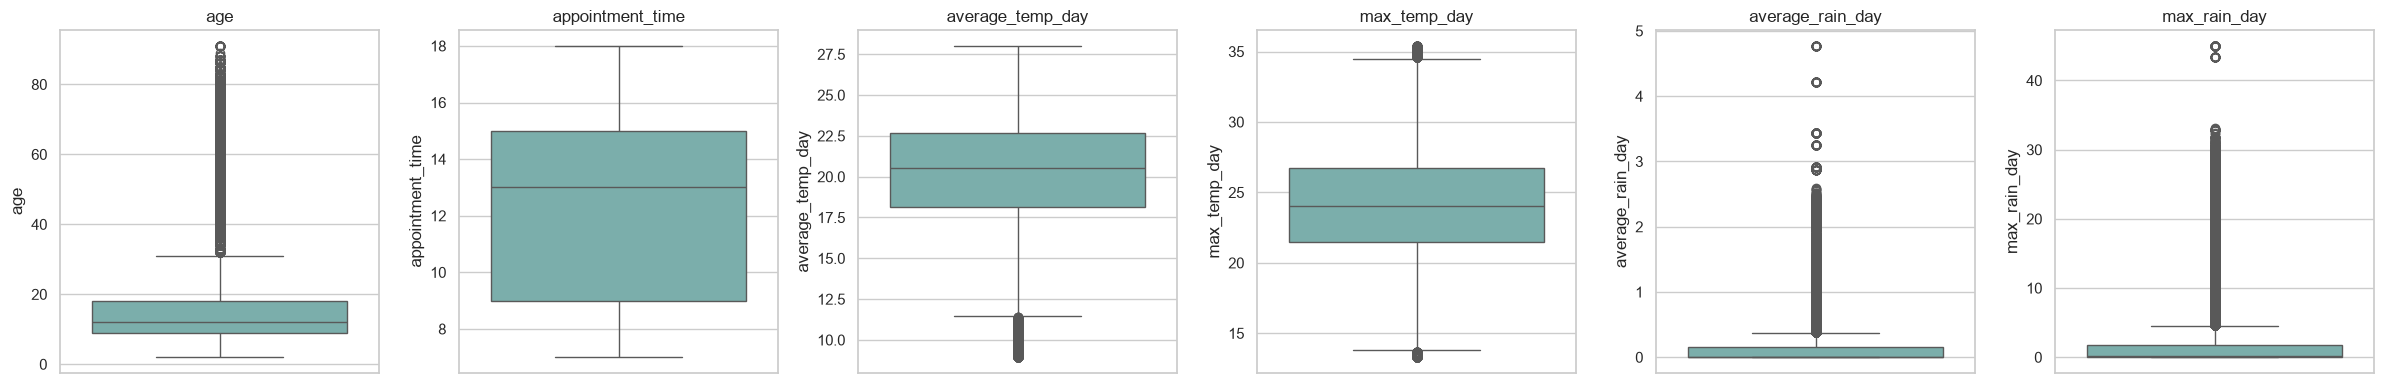

In [62]:
# Apply the age-outlier policy when this diagnostic cell is run independently.
age_outlier_threshold = 100
age_outlier_count = int(df['age'].gt(age_outlier_threshold).sum())
df = df.loc[df['age'].isna() | df['age'].le(age_outlier_threshold)].copy()
print(f'Removed {age_outlier_count} records with age above {age_outlier_threshold}.')

# IQR outlier detection for continuous numeric fields.
outlier_columns = [column for column in ['age', 'appointment_time', 'avg_temp', 'average_temp_day', 'max_temp', 'max_temp_day', 'avg_rain', 'average_rain_day', 'max_rain', 'max_rain_day'] if column in df.columns]
outlier_summary = []
for column in outlier_columns:
    values = pd.to_numeric(df[column], errors='coerce').dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outlier_count = int(((values < lower_bound) | (values > upper_bound)).sum())
    outlier_summary.append({'feature': column, 'lower_bound': lower_bound, 'upper_bound': upper_bound, 'outlier_count': outlier_count, 'outlier_pct': outlier_count / len(values) * 100})

outlier_summary = pd.DataFrame(outlier_summary).sort_values('outlier_count', ascending=False)
display(outlier_summary.round(2))

fig, axes = plt.subplots(1, len(outlier_columns), figsize=(4 * len(outlier_columns), 4))
axes = [axes] if len(outlier_columns) == 1 else axes
for ax, column in zip(axes, outlier_columns):
    sns.boxplot(y=df[column], ax=ax, color='#72B7B2')
    ax.set_title(column)
    ax.set_xlabel('')
plt.tight_layout()
plt.show()


## Interpretation note\n\nThe charts are descriptive, not causal. Preserve missingness in later modeling and ensure all predictor values are known before the appointment.\n

## Duplicate-record removal\n
\n
Exact duplicate rows are removed from this notebook analysis and its encoded output. The original source CSV is not changed.\n

In [5]:
# Remove exact duplicate appointments before outlier handling and encoding.\n
duplicate_record_count = int(df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print(f'Removed {duplicate_record_count} exact duplicate records.')

Removed 0 exact duplicate records.
